# Cookie Cats A/B Test

## Gate Placement and Player Retention

**Notebook:** 03_business_analysis.ipynb  
**Phase:** 2 — Business Analysis  
**Source:** BigQuery table `cookie_cats.clean_cookie_cats`, 90,189 players, built from Kaggle "Mobile Games: A/B Testing" (`cookie_cats.csv`), originally from DataCamp project 184  
**Author:** Taofeek Salami  
**Date:** 2026-10-20  

## Describe the Test Groups and Their Outcomes

This notebook first checks that the group sizes match the planned 50/50 split (sample ratio test), then describes 1-day retention, 7-day retention and game rounds by version. All results are descriptive: they record what each version showed and do not test whether the differences are statistically significant. The queries are the same as in `sql/02_business_analysis.sql`.

In [1]:
import os                            # reads settings from environment variables
from pathlib import Path             # builds file paths from the project root

from dotenv import load_dotenv       # loads the .env file into environment variables
from google.cloud import bigquery    # Google's Python client for BigQuery
from scipy.stats import chisquare    # chi-square goodness-of-fit test for the sample ratio check
import matplotlib.pyplot as plt      # draws the charts
import numpy as np                   # bar positions and histogram bin edges

## Configuration

Settings come from `.env`. The sample ratio settings are the values fixed in `PROJECT_INFO.md` → Decision Rules before the test was run.

In [2]:
# The notebook runs from notebooks/, so the project root is one folder up.
PROJECT_ROOT = Path.cwd().resolve().parent
load_dotenv(PROJECT_ROOT / ".env")

PROJECT_ID = os.environ["GCP_PROJECT_ID"]
DATASET = os.environ["BQ_DATASET"]
LOCATION = os.environ["BQ_LOCATION"]

TABLE_ID = f"{PROJECT_ID}.{DATASET}.clean_cookie_cats"

# Sample ratio test settings (PROJECT_INFO.md → Decision Rules).
EXPECTED_SHARE = {"gate_30": 0.5, "gate_40": 0.5}   # assumed 50/50 allocation (A-009)
SRM_ALERT_P = 0.001                                  # below this, comparisons between versions are paused

client = bigquery.Client(project=PROJECT_ID, location=LOCATION)
print(TABLE_ID)

OUTPUT_DIR = PROJECT_ROOT / "outputs"

# One colour per version, used in every chart. The pair was checked for
# separation under colour-vision deficiency and for contrast on a white background.
VERSION_COLOURS = {"gate_30": "#2a78d6", "gate_40": "#eb6834"}
VERSIONS = ["gate_30", "gate_40"]
ROUNDS_CAP = 250   # same x-axis cap as the Phase 1 histogram


def run_query(sql):
    """Run a query in BigQuery and return the result as a pandas DataFrame."""
    return client.query(sql).to_dataframe()

cookie-cats-ab-taofeek.cookie_cats.clean_cookie_cats


## 2.0 Sample Ratio Test

Checks whether the observed group sizes are consistent with a 50/50 split. A p-value below 0.001 would indicate a sample ratio mismatch: a problem with assignment or data collection that would make comparisons between versions unreliable. A higher p-value means no evidence of a mismatch, not proof that assignment was random.

In [3]:
# 2.0 Same count as sql/02_business_analysis.sql, Section 0.
group_sizes = client.query(f"""
    SELECT version, COUNT(*) AS players
    FROM `{TABLE_ID}`
    GROUP BY version
    ORDER BY version
""").to_dataframe()

total_players = group_sizes["players"].sum()
group_sizes["share"] = group_sizes["players"] / total_players
group_sizes["expected_players"] = group_sizes["version"].map(EXPECTED_SHARE) * total_players

# chisquare compares observed with expected counts. With two groups the test has
# one degree of freedom. Expected counts must add up to the observed total,
# which they do because the expected shares sum to 1.
statistic, p_value = chisquare(f_obs=group_sizes["players"], f_exp=group_sizes["expected_players"])

print(group_sizes.to_string(index=False))
print(f"\nChi-square statistic: {statistic:.3f}")
print(f"p-value: {p_value:.4f}")
if p_value < SRM_ALERT_P:
    print("Sample ratio mismatch: comparisons between versions are paused")
else:
    print(f"No evidence of a sample ratio mismatch at the {SRM_ALERT_P} threshold")

version  players     share  expected_players
gate_30    44700  0.495626           45094.5
gate_40    45489  0.504374           45094.5

Chi-square statistic: 6.902
p-value: 0.0086
No evidence of a sample ratio mismatch at the 0.001 threshold


**Result.** gate_30 has 44,700 players (49.56%) and gate_40 has 45,489 (50.44%), against 45,094.5 each under a 50/50 split. The chi-square statistic is 6.902 with p = 0.0086. This is above the 0.001 alert threshold set in Decision Rules, so no sample ratio mismatch is flagged and the version comparisons go ahead. The p-value is below 0.05, so the imbalance is unusual for a true 50/50 split. It is reported here and carried into the Phase 4 validity notes. Passing this check does not show that assignment was random (A-002).

## 2.1 Retention by Version

Players retained at day 1 and day 7 in each version. The queries in this section are the same as in `sql/02_business_analysis.sql`, Section 1.

In [4]:
# 2.1 Retained players and retention rate per version.
retention = run_query(f"""
    SELECT
      version,
      COUNT(*)                                          AS players,
      COUNTIF(retention_1)                              AS retained_day1,
      ROUND(100 * AVG(CAST(retention_1 AS INT64)), 2)   AS retention_1_pct,
      COUNTIF(retention_7)                              AS retained_day7,
      ROUND(100 * AVG(CAST(retention_7 AS INT64)), 2)   AS retention_7_pct
    FROM `{TABLE_ID}`
    GROUP BY version
    ORDER BY version
""")
print(retention.to_string(index=False))

version  players  retained_day1  retention_1_pct  retained_day7  retention_7_pct
gate_30    44700          20034            44.82           8502            19.02
gate_40    45489          20119            44.23           8279            18.20


In [5]:
# 2.2 Gap between versions, gate_40 − gate_30, in percentage points and relative to gate_30.
retention_gaps = run_query(f"""
    WITH rates AS (
      SELECT
        AVG(IF(version = 'gate_30', CAST(retention_1 AS INT64), NULL)) AS r1_30,
        AVG(IF(version = 'gate_40', CAST(retention_1 AS INT64), NULL)) AS r1_40,
        AVG(IF(version = 'gate_30', CAST(retention_7 AS INT64), NULL)) AS r7_30,
        AVG(IF(version = 'gate_40', CAST(retention_7 AS INT64), NULL)) AS r7_40
      FROM `{TABLE_ID}`
    )
    SELECT '1-day retention' AS metric,
           ROUND(100 * r1_30, 2) AS gate_30_pct, ROUND(100 * r1_40, 2) AS gate_40_pct,
           ROUND(100 * (r1_40 - r1_30), 2) AS gap_pp,
           ROUND(100 * (r1_40 - r1_30) / r1_30, 2) AS relative_gap_pct
    FROM rates
    UNION ALL
    SELECT '7-day retention',
           ROUND(100 * r7_30, 2), ROUND(100 * r7_40, 2),
           ROUND(100 * (r7_40 - r7_30), 2),
           ROUND(100 * (r7_40 - r7_30) / r7_30, 2)
    FROM rates
""")
print(retention_gaps.to_string(index=False))

         metric  gate_30_pct  gate_40_pct  gap_pp  relative_gap_pct
1-day retention        44.82        44.23   -0.59             -1.32
7-day retention        19.02        18.20   -0.82             -4.31


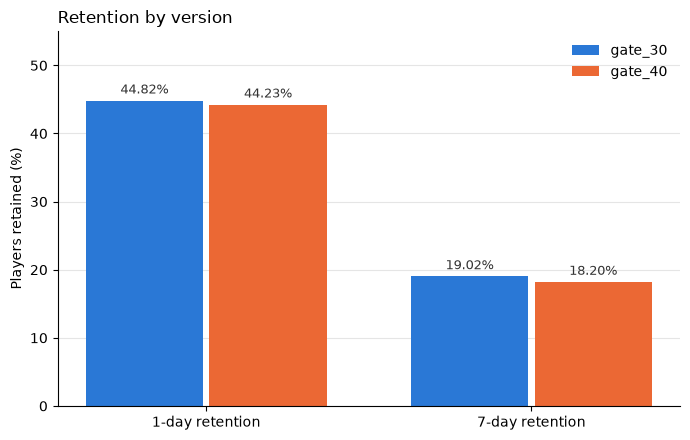

In [6]:
# Grouped bar chart: one group per retention metric, one bar per version.
metrics = ["retention_1_pct", "retention_7_pct"]
metric_labels = ["1-day retention", "7-day retention"]
positions = np.arange(len(metrics))
bar_width = 0.36

fig, ax = plt.subplots(figsize=(7, 4.5))
by_version = retention.set_index("version")
for i, version in enumerate(VERSIONS):
    values = [by_version.loc[version, m] for m in metrics]
    # Shift each version's bar left or right of the group centre; the extra 0.02
    # leaves a small gap between the two bars.
    offset = (i - 0.5) * (bar_width + 0.02)
    bars = ax.bar(positions + offset, values, bar_width,
                  color=VERSION_COLOURS[version], label=version)
    # Value labels on each bar, so the chart can be read without the axis.
    ax.bar_label(bars, labels=[f"{v:.2f}%" for v in values],
                 padding=3, fontsize=9, color="#333333")

ax.set_xticks(positions, metric_labels)
ax.set_ylabel("Players retained (%)")
ax.set_ylim(0, 55)   # bars start at zero so their length matches the value
ax.set_title("Retention by version", loc="left")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e5e5e5", linewidth=0.8)
ax.set_axisbelow(True)   # grid lines behind the bars
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "chart_retention_by_version.png", dpi=150)
plt.show()

## 2.3 Game Rounds by Version

Game rounds are the exploratory guardrail. They were recorded after assignment, so they are described as an outcome and are not used to split players into groups for the version comparison. Same query as `sql/02_business_analysis.sql`, Section 2.

In [7]:
# 2.3 Distribution summary of game rounds per version.
rounds_summary = run_query(f"""
    WITH quartiles AS (
      SELECT DISTINCT
        version,
        PERCENTILE_CONT(sum_gamerounds, 0.25) OVER (PARTITION BY version) AS p25_rounds,
        PERCENTILE_CONT(sum_gamerounds, 0.50) OVER (PARTITION BY version) AS median_rounds,
        PERCENTILE_CONT(sum_gamerounds, 0.75) OVER (PARTITION BY version) AS p75_rounds
      FROM `{TABLE_ID}`
    ),
    summary AS (
      SELECT
        version,
        COUNT(*) AS players,
        SUM(sum_gamerounds) AS total_rounds,
        ROUND(AVG(sum_gamerounds), 2) AS mean_rounds,
        ROUND(AVG(IF(NOT is_extreme_gamerounds, sum_gamerounds, NULL)), 2) AS mean_rounds_excl_extreme,
        MAX(sum_gamerounds) AS max_rounds,
        ROUND(100 * COUNTIF(is_zero_gamerounds) / COUNT(*), 2) AS zero_rounds_pct
      FROM `{TABLE_ID}`
      GROUP BY version
    )
    SELECT s.version, s.players, s.total_rounds,
           q.p25_rounds, q.median_rounds, q.p75_rounds,
           s.mean_rounds, s.mean_rounds_excl_extreme, s.max_rounds, s.zero_rounds_pct
    FROM summary AS s
    JOIN quartiles AS q USING (version)
    ORDER BY s.version
""")
print(rounds_summary.to_string(index=False))

version  players  total_rounds  p25_rounds  median_rounds  p75_rounds  mean_rounds  mean_rounds_excl_extreme  max_rounds  zero_rounds_pct
gate_30    44700       2344795         5.0           17.0        50.0        52.46                     51.34       49854             4.33
gate_40    45489       2333530         5.0           16.0        52.0        51.30                     51.30        2640             4.52


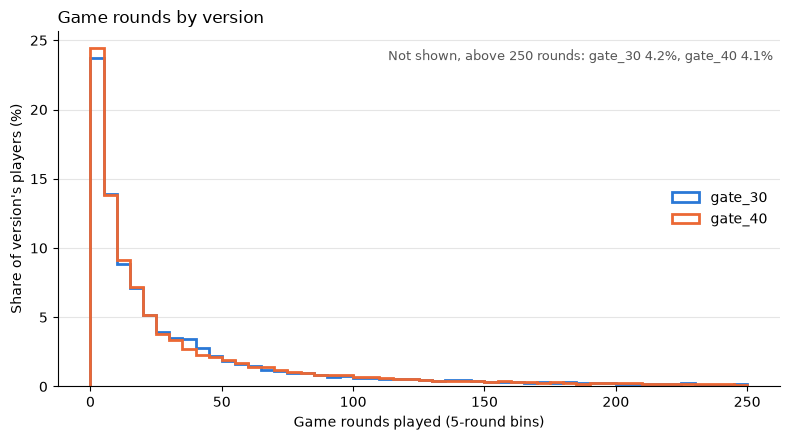

In [8]:
# One row per player: needed to draw the distribution.
rounds = run_query(f"SELECT version, sum_gamerounds FROM `{TABLE_ID}`")

bins = np.arange(0, ROUNDS_CAP + 5, 5)   # 5-round bins from 0 up to the cap

fig, ax = plt.subplots(figsize=(8, 4.5))
for version in VERSIONS:
    values = rounds.loc[rounds["version"] == version, "sum_gamerounds"]
    # Each player counts as 100 / (players in that version), so each bar is the
    # percentage of that version's players and the two versions compare fairly
    # despite different group sizes. Players above the cap fall outside the bins.
    weights = np.full(len(values), 100 / len(values))
    ax.hist(values, bins=bins, weights=weights, histtype="step", linewidth=2,
            color=VERSION_COLOURS[version], label=version)

# Share of each version beyond the cap, so the reader knows what is not shown.
above_cap = (rounds["sum_gamerounds"] > ROUNDS_CAP).groupby(rounds["version"]).mean() * 100

ax.set_xlabel("Game rounds played (5-round bins)")
ax.set_ylabel("Share of version's players (%)")
ax.set_title("Game rounds by version", loc="left")
ax.text(0.99, 0.95,
        f"Not shown, above {ROUNDS_CAP} rounds: "
        f"gate_30 {above_cap['gate_30']:.1f}%, gate_40 {above_cap['gate_40']:.1f}%",
        transform=ax.transAxes, ha="right", va="top", fontsize=9, color="#555555")
ax.legend(frameon=False, loc="center right")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e5e5e5", linewidth=0.8)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "chart_gamerounds_by_version.png", dpi=150)
plt.show()

## 2.4 Retention Patterns by Version

Share of each version retained on neither day, day 1 only, day 7 only, or both days. Same query as `sql/02_business_analysis.sql`, Section 3.

In [9]:
# 2.4 Retention combinations; percentages add up to 100 within each version.
retention_patterns = run_query(f"""
    SELECT
      version,
      CASE
        WHEN retention_1 AND retention_7 THEN 'Both days'
        WHEN retention_1                 THEN 'Day 1 only'
        WHEN retention_7                 THEN 'Day 7 only'
        ELSE 'Neither'
      END AS retention_pattern,
      COUNT(*) AS players,
      ROUND(100 * COUNT(*) / SUM(COUNT(*)) OVER (PARTITION BY version), 2) AS pct_of_version
    FROM `{TABLE_ID}`
    GROUP BY version, retention_pattern
    ORDER BY retention_pattern, version
""")
print(retention_patterns.to_string(index=False))

version retention_pattern  players  pct_of_version
gate_30         Both days     6676           14.94
gate_40         Both days     6506           14.30
gate_30        Day 1 only    13358           29.88
gate_40        Day 1 only    13613           29.93
gate_30        Day 7 only     1826            4.09
gate_40        Day 7 only     1773            3.90
gate_30           Neither    22840           51.10
gate_40           Neither    23597           51.87


## Observations

All results in this notebook are descriptive. They record what each version showed and do not test whether the differences are larger than chance alone would produce; that is Phase 4.

- **Sample ratio:** the split is 49.56% gate_30 and 50.44% gate_40 (p = 0.0086). This is above the 0.001 alert threshold, so the comparisons below go ahead; the imbalance is carried into the Phase 4 validity notes.
- **7-day retention (primary):** 18.20% for gate_40 against 19.02% for gate_30, a gap of −0.82 percentage points (−4.31% relative to gate_30). At gate_40's group size, the gap corresponds to about 373 players.
- **1-day retention (secondary):** 44.23% for gate_40 against 44.82% for gate_30, a gap of −0.59 percentage points (−1.32% relative).
- **Retention patterns:** the share retained at day 1 only is almost the same in both versions (29.88% and 29.93%). gate_40 has lower shares retained on both days (14.30% vs 14.94%) and on day 7 only (3.90% vs 4.09%), and a higher share retained on neither day (51.87% vs 51.10%). The 7-day gap is in players retained at day 7, not in players who returned only on day 1.
- **Game rounds (guardrail, exploratory):** the distributions are similar. The median is 17 for gate_30 and 16 for gate_40, the quartiles are 5 and 50 against 5 and 52, and the means without the flagged extreme player are 51.34 and 51.30. Total rounds are higher for gate_30 (2,344,795 against 2,333,530) only because of the single player with 49,854 rounds; without that player, the gate_30 total is 2,294,941.
- **Zero-round players:** 4.33% of gate_30 and 4.52% of gate_40.

Questions for Phases 3 and 4: whether the 7-day and 1-day gaps are larger than chance would produce, which test suits the skewed game-round distribution, and the smallest difference this sample could reliably detect.